<a href="https://colab.research.google.com/github/mugalan/vibration-analysis/blob/main/answers-to-selected-assignments/ME421_Worked_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME421 — Open-ended vibration modelling laboratory
## Fully worked illustrative solution (Weeks 1–4)
This is one possible solution to the companion laboratory notebook. All dimensions, tension, masses, dashpot settings, absorber constraints and recordings used in the numerical example are **synthetic**, not specifications or measurements of the TM1016V. The apparatus datasheet confirms the displacement sensor, exciter encoder, accelerometer, variable-area dashpot and undamped vibration absorber, but does not establish the numerical values or all mounting options used here. Check the supplied user guide and physical apparatus before implementation. In particular, axial tension is an assumption of the laboratory problem, not a stated feature of the datasheet.

Run the notebook from top to bottom. It generates example CSV files and then imports them as if they were experimental recordings. For real measurements, set `SYNTHETIC = False` in the setup cell and place appropriately formatted recordings in `me421_measured_data`. The synthetic generators are then skipped and measured CSV files are not overwritten. The example uses SI units throughout; plots show millimetres and Hz where convenient.

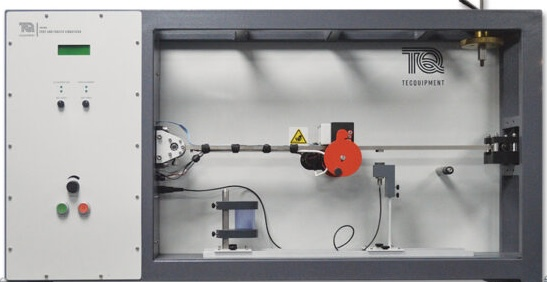

## Resources

- [TecQuipment vibration analyser — video](https://youtu.be/r_ouYEYhR5U)
- [Vibration analysis — Python resources](https://github.com/mugalan/vibration-analysis)
- TecQuipment TM1016V Free and Forced Vibrations datasheet and the user guide available in the laboratory.

The apparatus provides non-contact displacement measurements, acceleration measurements at the exciter, rotational speed and exciter angular position. The VDAS system can also derive velocity and acceleration from displacement measurements. Available components include an adjustable viscous dashpot, additional masses and an undamped vibration absorber. Establish the permissible configurations and adjustment ranges of the actual apparatus before designing experiments.

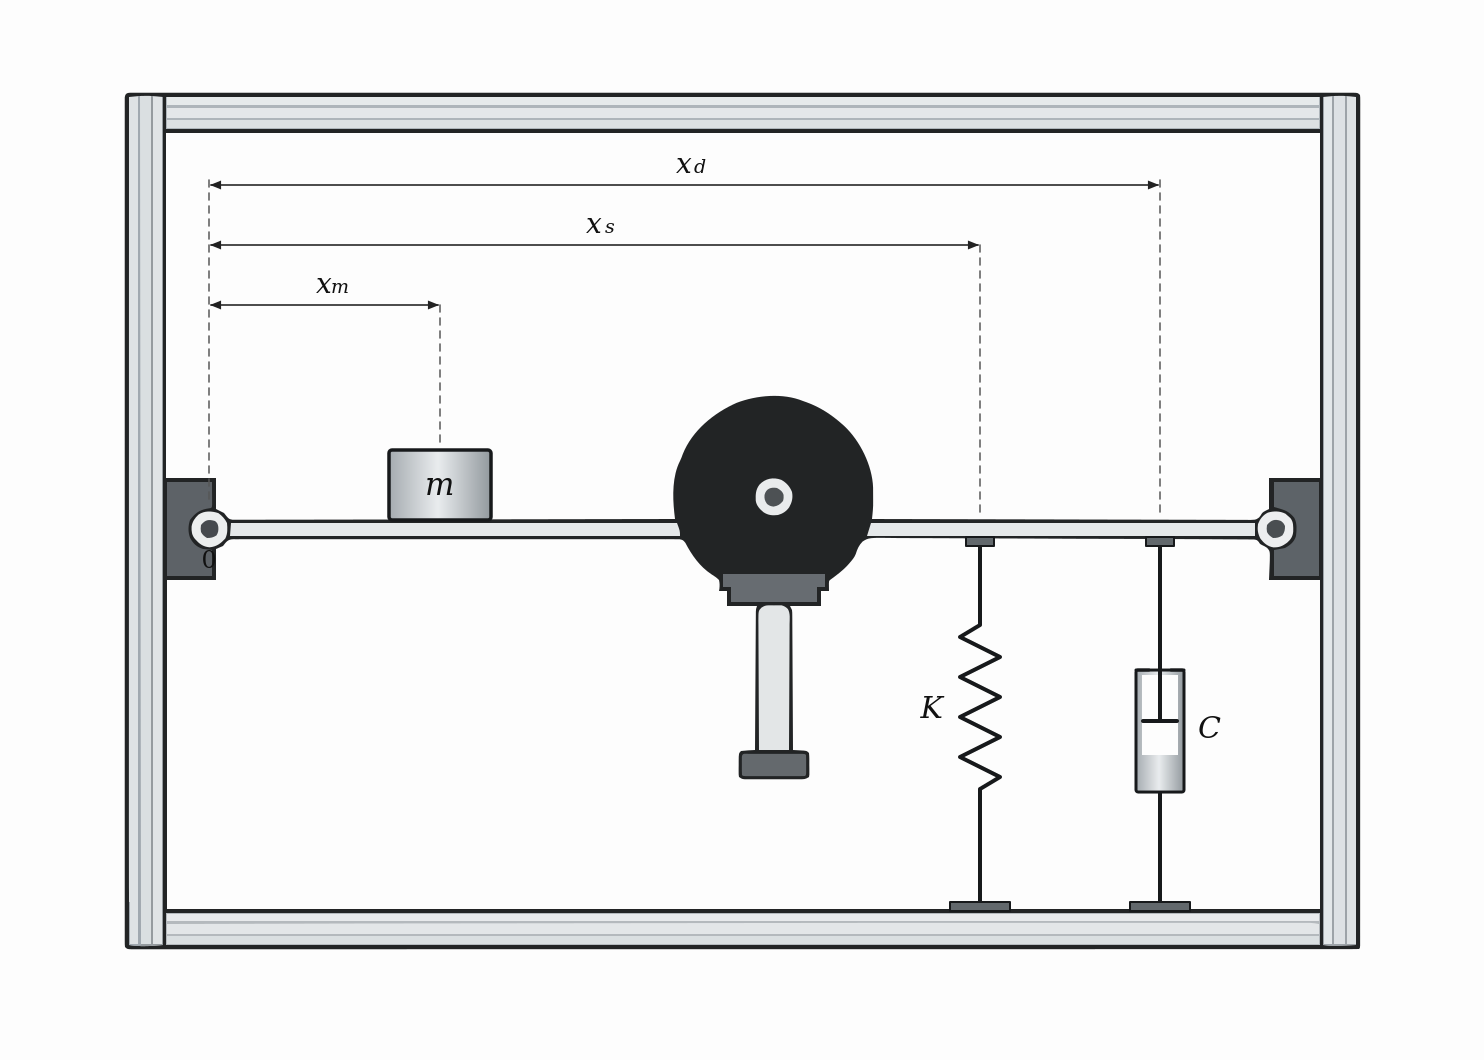

# Part I — Modelling, identification and validation (Weeks 1–2)

## Week 1 — Activity 1: Mathematical formulation

### Governing equation and spatial decomposition

Consider the pinned–pinned Euler–Bernoulli beam under constant axial tension $T>0$. Let $y(x,t)$ be its small transverse displacement from static equilibrium. The beam carries concentrated masses $m_i$ at $x_i$ (including the translating exciter mass), a grounded dashpot $c_d$ at $x_d$, and a rotating unbalance $u=m_r e$ at $x_f$.

As in the augmented-beam answer to the [Exercise 3.4 in the vibrations note](https://github.com/mugalan/vibration-analysis/blob/main/class-notes/Vibrations-DHSM.pdf), represent the localised forces using Dirac delta distributions:


$$
\begin{aligned}
\rho A y_{tt}+EI y_{xxxx}-T y_{xx}+\mathscr C_s y_t
&+\sum_i m_i\delta(x-x_i)y_{tt}(x_i,t)\\
&+c_d\delta(x-x_d)y_t(x_d,t)
=u\omega^2\cos(\omega t)\delta(x-x_f).
\end{aligned}
$$

Here $\mathscr C_s$ represents inherent damping; its modal action will be specified below. The equation is understood distributionally. The dashpot's added inertia and stiffness are initially neglected.

The reference spatial operator is

$$
\mathscr L=\frac{EI}{\rho A}\frac{d^4}{dx^4}
-\frac{T}{\rho A}\frac{d^2}{dx^2},
$$

on $H^4(0,L)$ with $y=y_{xx}=0$ at both ends. With the inner product

$$
\langle\langle\phi,\psi\rangle\rangle=\frac{2}{L}\int_0^L\phi(x)\psi(x)\,dx,
$$

the operator is self-adjoint and positive, with the complete orthonormal sine basis

$$
\psi_k(x)=\sin\left(\frac{k\pi x}{L}\right),\qquad
\mathscr L\psi_k=\omega_{0k}^2\psi_k,
\quad
\omega_{0k}^2=\frac{EI}{\rho A}\left(\frac{k\pi}{L}\right)^4+
\frac{T}{\rho A}\left(\frac{k\pi}{L}\right)^2.
$$

Retain the first $n$ basis functions and write

$$
y(x,t)\approx\Psi^T(x)z(t),\qquad
\Psi(x)=[\psi_1(x),\ldots,\psi_n(x)]^T.
$$

### Finite-dimensional model

Project the governing equation onto $\psi_j$, using orthonormality and
$\frac{2}{L}\int_0^L\psi_j(x)\delta(x-a)\,dx=\frac{2}{L}\psi_j(a)$.
With $m_b=\rho AL$, the resulting equations are

$$
\boxed{
M\ddot z+\left(A_s+\frac{2c_d}{m_b}bb^T\right)\dot z+
K_0z=\frac{2u\omega^2}{m_b}\Psi(x_f)\cos(\omega t),
}
$$

where

$$
M=I_n+\sum_i\frac{2m_i}{m_b}\Psi(x_i)\Psi^T(x_i),
\qquad K_0=\operatorname{diag}(\omega_{01}^2,\ldots,\omega_{0n}^2),
\qquad b=\Psi(x_d).
$$

The inherent damping matrix has entries $(A_s)_{jk}=\langle\langle\psi_j,\mathscr C_s\psi_k\rangle\rangle/(\rho A)$ (interpreted weakly if needed). Each attached mass and the dashpot contributes a symmetric rank-one update. Thus $M$ and $K_0$ are positive definite, but the reference modal equations are generally coupled.

### Natural modes of the mass-loaded beam

Solve the undamped generalized eigenvalue problem

$$
K_0\bar z_k=\omega_k^2 M\bar z_k,\qquad
V=[\bar z_1,\ldots,\bar z_n],\qquad V^TMV=I_n.
$$

Equivalently, $\Omega=M^{-1}K_0$ has eigenvalues $\omega_k^2$. With $z=Vq$,

$$
y(x,t)\approx\sum_{k=1}^n q_k(t)\chi_k(x),
\qquad \chi_k(x)=\Psi^T(x)\bar z_k.
$$

The $\psi_k$ are the reference basis; the $\chi_k$ approximate the natural modes of the mass-loaded beam.

Assume classical inherent damping, so that
$V^TA_sV=D_s=\operatorname{diag}(2\zeta_k\omega_k)$.
Premultiplying the transformed equations by $V^T$ gives

$$
\boxed{
\ddot q+D\dot q+\Lambda q=\frac{2u\omega^2}{m_b}p\cos(\omega t),
\qquad
D=D_s+\frac{2c_d}{m_b}gg^T,
}
$$

where $\Lambda=\operatorname{diag}(\omega_k^2)$,
$g=V^T\Psi(x_d)$ and $p=V^T\Psi(x_f)$.

Classical inherent damping preserves the uncoupled natural modes; the external dashpot generally couples them. The unknown $\zeta_k$ and $c_d$ must be identified or explicitly assumed.

### Measurements and modal truncation

Let $h=V^T\Psi(x_m)$, where $x_m$ denotes the displacement sensor location (not a mass location in this notebook). Then

$$
y(x_m,t)\approx h^Tq,\qquad
y_{tt}(x_f,t)\approx p^T\ddot q.
$$

For symmetric attached masses and midpoint excitation, antisymmetric modes have $p_k=0$; a midpoint sensor also has $h_k=0$ for these modes. An off-centre dashpot can nevertheless excite them indirectly through $gg^T$.

For a reduced model, retain the corresponding entries of $q,g,p,h$ and principal submatrices of $D,\Lambda$, denoted by subscript $r$. Compare the first mode, the first two directly excited symmetric modes, and larger models. Determine the actual modal ordering numerically rather than assuming that symmetric modes have indices 1 and 3.

### Harmonic response and first-mode approximation

For $q_r(t)=\operatorname{Re}(\widehat q_r e^{i\omega t})$, the harmonic particular solution is

$$
\widehat q_r=\frac{2u\omega^2}{m_b}
(\Lambda_r-\omega^2I+i\omega D_r)^{-1}p_r.
$$

The displacement and acceleration amplitudes are obtained from
$\widehat y=h_r^T\widehat q_r$ and
$\widehat a=-\omega^2p_r^T\widehat q_r$.
Amplitude is the modulus; phase lag is $-\arg\widehat y$.
These are asymptotic steady-state responses when the free response decays.

Near the first resonance, retaining only mode 1 gives

$$
\ddot q_1+2\zeta_{1,\mathrm{eff}}\omega_1\dot q_1+\omega_1^2q_1
=\frac{2u\omega^2p_1}{m_b}\cos(\omega t),
\qquad
\zeta_{1,\mathrm{eff}}=\zeta_1+\frac{c_dg_1^2}{m_b\omega_1}.
$$

Hence

$$
\boxed{\widehat y=
\frac{2u\omega^2h_1p_1/m_b}
{\omega_1^2-\omega^2+2i\zeta_{1,\mathrm{eff}}\omega_1\omega}.}
$$

Identify $\zeta_1$ and $c_d(s)$ using free-decay measurements, validate against independent forced-response data, and compare model orders before adopting this approximation for absorber design. First-mode data alone do not identify higher-mode damping.

In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import eigh
from scipy.optimize import least_squares
from scipy.integrate import solve_ivp
from pathlib import Path
from IPython.display import display

rng = np.random.default_rng(421)

SYNTHETIC = True  # False: read existing measured recordings, never generate them
DATA = Path('me421_dummy_data' if SYNTHETIC else 'me421_measured_data')
DATA.mkdir(exist_ok=True)

# Illustrative values only; replace with measured geometry and masses.
L, rho, E, width, thickness, T = .80, 7850., 200e9, .025, .004, 100.

A = width * thickness
I = width * thickness**3 / 12

# Total mass of the beam
mb = rho * A * L

# Exciter, measurement and dashpot locations
xf, xm, xd = L/2, L/2, L*.40

# Exciter mass and rotating unbalance
me, u = 1.2, 2.0e-5  # kg, kg m

attached = [(me, xf)]


def basis(x, n):
    """
    Orthonormal spatial basis functions with respect to
    the normalized spatial inner product.
    """
    return np.sin(np.arange(1, n+1) * np.pi * x / L)


def beam(n):
    """
    Construct the normalized mathematical model of the
    mass-loaded beam and compute its natural modes.
    """

    # Dimensionless mass matrix
    M = np.eye(n)

    for mass, x in attached:
        v = basis(x, n)
        M += (2 * mass / mb) * np.outer(v, v)

    # Natural frequencies squared of the unperturbed beam
    k = np.arange(1, n+1) * np.pi / L

    w0_squared = (
        E * I * k**4 + T * k**2
    ) / (rho * A)

    # Normalized stiffness matrix
    K0 = np.diag(w0_squared)

    # Inertia-normalized stiffness operator
    Omega = np.linalg.solve(M, K0)

    # Solve the equivalent generalized eigenvalue problem
    # K0 v = w^2 M v
    #
    # eigh automatically ensures V.T @ M @ V = I
    w2, V = eigh(K0, M)

    for j in range(n):
        pivot = np.argmax(np.abs(V[:, j]))
        V[:, j] *= np.sign(V[pivot, j])
    w = np.sqrt(w2)

    return M, Omega, w, V


# Construct the beam model
n = 9

M, Omega, w, V = beam(n)

# Modal excitation factors
p = V.T @ basis(xf, n)

# Modal damping-location factors
g = V.T @ basis(xd, n)

# Modal measurement factors
h = V.T @ basis(xm, n)

print('Beam mass (kg):', mb)

display(pd.DataFrame({
    'mode': np.arange(1, n+1),
    'frequency_Hz': w / (2*np.pi),
    'excitation_coupling': p,
    'dashpot_coupling': g,
    'measurement_coupling': h
}))

# Spatial convergence: first two directly excited modes and attachment factors
convergence = []
for nbasis in [3, 5, 9, 15, 25, 41]:
    _, _, wn, Vn = beam(nbasis)
    pn = Vn.T @ basis(xf, nbasis)
    gn = Vn.T @ basis(xd, nbasis)
    hn = Vn.T @ basis(xm, nbasis)
    an = Vn.T @ basis(L/2, nbasis)
    jj = np.flatnonzero(np.abs(pn) > 1e-8*np.max(np.abs(pn)))[:2]
    for rank, j in enumerate(jj, 1):
        convergence.append(dict(basis_size=nbasis, symmetric_rank=rank,
            mode=j+1, frequency_Hz=wn[j]/(2*np.pi),
            p_abs=abs(pn[j]), g_abs=abs(gn[j]), h_abs=abs(hn[j]),
            a_mid_abs=abs(an[j])))
display(pd.DataFrame(convergence).round(6))
# Absolute factors avoid arbitrary eigenvector sign changes.
# Nine modes are retained for the illustrative instrument; check convergence
# against the larger spatial models before using this choice for real design.

# Verify the eigenvector normalization
print('Mass normalization error:',
      np.linalg.norm(V.T @ M @ V - np.eye(n)))

# Verify the modal decomposition
print('Modal decomposition error:',
      np.linalg.norm(Omega @ V - V @ np.diag(w**2)))

In [ ]:
# Retain the first two directly excited modes
tol = 1e-8 * np.max(np.abs(p))
idx = np.flatnonzero(np.abs(p) > tol)[:2]

wr = w[idx]
Vr = V[:, idx]

pr = p[idx]
gr = g[idx]
hr = h[idx]

Lambda_r = np.diag(wr**2)

# Display the retained modal properties
display(pd.DataFrame({
    'Mode': idx + 1,
    'Natural frequency (rad/s)': wr,
    'Natural frequency (Hz)': wr / (2*np.pi),
    'Excitation factor': pr,
    'Dashpot factor': gr,
    'Measurement factor': hr
}))

# Plot the retained spatial mode shapes
x = np.linspace(0, L, 301)

plt.figure(figsize=(10, 4))

for j, k in enumerate(idx):
    chi = np.array([
        basis(xx, n) @ Vr[:, j]
        for xx in x
    ])

    plt.plot(x, chi, label=fr'$\chi_{{{k+1}}}(x)$')

plt.axvline(xd, color='black', ls='--', label='Dashpot')
plt.axvline(xf, color='gray', ls=':', label='Exciter')
plt.axhline(0, color='black', lw=0.5)

plt.xlabel('$x$ (m)')
plt.ylabel('Mass-normalized mode shape')
plt.title('Retained natural modes of the mass-loaded beam')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Activity 2 — experimental plan and preliminary simulations
Use repeated free-decay experiments with the dashpot removed and at several settings. Keep masses, tension and positions unchanged. Record displacement versus time after release; use two initial amplitudes and repeat at each setting to assess repeatability and amplitude dependence. A separate forced-response sweep will validate the fitted model rather than being used for calibration. Wait for transients to decay before collecting each steady-state record; use sufficiently fine frequency spacing near peaks. Verify safe amplitudes, motor speed, attachment security, sensor travel and dashpot settings with staff before any run. The sensor and exciter are assumed co-located here for simplicity.

For an underdamped first mode, the free response is
$$y(t)=e^{-\sigma t}[B\cos(\omega_dt)+D\sin(\omega_dt)]+y_0,\quad \omega_n=\sqrt{\omega_d^2+\sigma^2},\quad\zeta=\sigma/\omega_n.$$
For harmonic forcing, the complex steady-state displacement is
$$\widehat y=\frac{2u\omega^2h_1p_1/m_b}{\omega_1^2-\omega^2+i\omega(2\zeta_1\omega_1+2c_dg_1^2/m_b)}.$$
The rotating unbalance force is not constant in amplitude; it scales as $\omega^2$. Phase lag is $-\arg\widehat y$ for the chosen convention. The following preliminary simulations use provisional damping values, not identified parameters.

In [ ]:
# First-mode properties from the modal decomposition
w1 = w[0]
f1 = w1 / (2 * np.pi)

p1 = p[0]  # Excitation factor
g1 = g[0]  # Dashpot attachment factor
h1 = h[0]  # Measurement factor

# Assumed inherent first-mode damping ratio
zeta_guess = 0.02


def H1(f, zeta1, cd=0):
    """
    Complex steady-state displacement response at the
    measurement location using the first-mode approximation.

    f     : excitation frequency (Hz)
    zeta1 : inherent first-mode damping ratio
    cd    : physical dashpot damping coefficient (N s/m)
    """
    om = 2 * np.pi * np.asarray(f)

    D1 = 2 * zeta1 * w1 + 2 * cd * g1**2 / mb

    return (
        (2 * u * om**2 / mb) * h1 * p1
        / (w1**2 - om**2 + 1j * om * D1)
    )


def first_mode_rhs(t, state, om, zeta1, cd=0, forced=True):
    """
    State-space representation of the normalized
    first-mode mathematical model.
    """
    q1, dq1 = state

    D1 = 2 * zeta1 * w1 + 2 * cd * g1**2 / mb

    force = (
        (2 * u * om**2 / mb) * p1 * np.cos(om * t)
        if forced else 0.0
    )

    ddq1 = force - D1 * dq1 - w1**2 * q1

    return [dq1, ddq1]


# --------------------------------------------------
# Free and forced vibration responses
# --------------------------------------------------

t = np.linspace(0, 4, 1601)

plt.figure(figsize=(12, 5))

for r in [0.75, 1.0, 1.25]:

    om = r * w1

    sol = solve_ivp(
        first_mode_rhs,
        [t[0], t[-1]],
        [0, 0],
        args=(om, zeta_guess, 0, True),
        t_eval=t,
        rtol=1e-7,
        atol=1e-9
    )

    plt.plot(
        t,
        1000 * h1 * sol.y[0],
        label=f'Forced: {r:.2f} f1'
    )


# Free vibration response
# Initial displacement of 1 mm at the measurement location

sol = solve_ivp(
    first_mode_rhs,
    [t[0], t[-1]],
    [0.001 / h1, 0],
    args=(0, zeta_guess, 0, False),
    t_eval=t,
    rtol=1e-7,
    atol=1e-9
)

plt.plot(
    t,
    1000 * h1 * sol.y[0],
    label='Free vibration',
    alpha=0.7
)

plt.xlabel('Time (s)')
plt.ylabel('Displacement (mm)')
plt.title('Free and forced vibration responses')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Steady-state amplitude response
# --------------------------------------------------

fgrid = np.linspace(0.65 * f1, 1.35 * f1, 501)

plt.figure(figsize=(10, 5))

for cd0 in [0, 0.5, 1.5]:

    plt.plot(
        fgrid,
        1000 * np.abs(H1(fgrid, zeta_guess, cd0)),
        label=f'$c_d={cd0:g}$ N s/m'
    )

plt.axvline(f1, color='black', ls='--', alpha=0.5,
            label='First natural frequency')

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Displacement amplitude (mm)')
plt.title('Influence of external viscous damping')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Steady-state phase response
# --------------------------------------------------

plt.figure(figsize=(10, 5))

for cd0 in [0, 0.5, 1.5]:

    phase = -np.angle(
        H1(fgrid, zeta_guess, cd0),
        deg=True
    )

    plt.plot(
        fgrid,
        phase,
        label=f'$c_d={cd0:g}$ N s/m'
    )

plt.axvline(f1, color='black', ls='--', alpha=0.5)

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Phase lag (degrees)')
plt.title('Influence of external damping on phase lag')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
def modal_operators(indices, zeta, cd, absorber=None):
    """Normalized operators for selected original beam modes."""
    indices = np.asarray(indices, dtype=int)
    wi, gi, pi, hi = w[indices], g[indices], p[indices], h[indices]
    D = np.diag(2*np.asarray(zeta)*wi) + (2*cd/mb)*np.outer(gi, gi)
    Om = np.diag(wi**2)
    ar = None
    if absorber is not None:
        mass, freq, location = absorber
        wa = 2*np.pi*freq
        ka = mass*wa**2
        ar = V[:, indices].T @ basis(location, n)
        D = np.pad(D, ((0,1),(0,1)))
        Om = np.block([[Om+(2*ka/mb)*np.outer(ar,ar), -(2*ka/mb)*ar[:,None]],
                       [-wa**2*ar[None,:], np.array([[wa**2]])]])
        pi = np.r_[pi, 0.]
    return D, Om, pi, hi, ar


def modal_response(f, indices, zeta, cd, absorber=None):
    """Complex sensor, exciter and relative absorber displacement amplitudes."""
    indices = np.asarray(indices, dtype=int)
    om = 2*np.pi*np.asarray(f)
    D, Om, pi, hi, ar = modal_operators(indices, zeta, cd, absorber)
    mat = Om-om[...,None,None]**2*np.eye(len(pi))+1j*om[...,None,None]*D
    force = (2*u/mb)*om[...,None]**2*pi
    Qhat = np.linalg.solve(mat, force[...,None])[...,0]
    qhat = Qhat[...,:len(indices)]
    stroke = None if ar is None else Qhat[...,-1]-qhat@ar
    return qhat@hi, qhat@p[indices], stroke


## Week 2 — Activity 3: dummy experimental recordings
The next cell acts as a virtual instrument. It uses a nine-function beam model, small measurement noise and run-to-run variation. Higher-mode damping is assumed only inside the synthetic generator; it is not estimated from the data. The unknown ground-truth coefficients must not be used in the estimator. CSV schemas are illustrative, not claimed VDAS export formats.

Free-decay columns: `setting` (-1 means dashpot removed; 0–1 are hypothetical installed settings), `run`, `time_s`, `displacement_m`. Forced-response columns additionally contain frequency, encoder angle and acceleration. The data are generated independently of the first-mode fitting procedure.

High-frequency modal components can exceed the Nyquist frequency of the illustrative free-decay sampling. The first-mode fit targets the low-frequency response; a real investigation of higher modes requires adequate sampling and anti-alias filtering. The optional synthetic stroke column is `relative_stroke_m`.

In [ ]:
# Synthetic instrument only.
# No ground-truth damping values are passed to the estimator.

from scipy.linalg import expm

# Use the full modal model for the synthetic instrument
N = len(w)

# Modal properties
Lambda = np.diag(w**2)

# Ground-truth inherent modal damping ratios
truth_zeta = np.r_[0.013, np.full(N-1, 0.018)]

Ds = np.diag(2 * truth_zeta * w)


def true_cd(s):
    """
    Ground-truth dashpot calibration function.

    s < 0 represents the absence of the external dashpot.
    Returns the physical damping coefficient in N s/m.
    """
    return 0.0 if s < 0 else 0.18 + 1.8 * s**1.4


# Dashpot settings
settings = [-1., 0., 0.25, 0.5, 0.75, 1.]

if SYNTHETIC:
    records = []

    # Sampling times
    tfree = np.arange(0, 5, 0.005)
    dt = tfree[1] - tfree[0]

    for s in settings:

        for run, amp in enumerate([0.0007, 0.0012, 0.0007, 0.0012]):

            # Introduce small run-to-run variations in dashpot damping
            cd = true_cd(s) * (1 + rng.normal(0, 0.012))

            # Normalized modal damping matrix
            D = Ds + (2 * cd / mb) * np.outer(g, g)

            # Initial modal displacements
            q0 = np.zeros(N)

            # First-mode displacement contribution at the sensor
            q0[0] = amp / h[0]

            # Introduce a small higher-mode contamination
            if N >= 3 and abs(h[2]) > 1e-8:
                q0[2] = 0.000003 / h[2]

            # State-space system matrix
            state_matrix = np.block([
                [np.zeros((N, N)), np.eye(N)],
                [-Lambda,          -D]
            ])

            # Uniform-step exact propagation
            P = expm(state_matrix * dt)

            # Initial state: modal displacements and velocities
            state = np.r_[q0, np.zeros(N)]

            # Simulate measured displacement
            y = np.empty(len(tfree))

            for j, ti in enumerate(tfree):

                y[j] = h @ state[:N]

                state = P @ state

            # Add measurement noise and a run-dependent sensor offset
            y += rng.normal(0, 1.8e-6, len(tfree))
            y += rng.normal(0, 2e-6)

            records.append(pd.DataFrame({
                'setting': s,
                'run': run,
                'time_s': tfree,
                'displacement_m': y
            }))


    # Save the synthetic experimental measurements
    free_decay = pd.concat(records, ignore_index=True)

    free_decay.to_csv(DATA / 'free_decay.csv', index=False)

    print('Created', DATA / 'free_decay.csv')


In [ ]:
# Import experimental data (replace path with actual exported data after column mapping).
free=pd.read_csv(DATA/'free_decay.csv')
display(free.head())
for s in [-1.,.5,1.]:
    data=free[(free.setting==s)&(free.run==1)]
    plt.plot(data.time_s,1000*data.displacement_m,label=f'setting {s:g}')
plt.xlabel('Time (s)'); plt.ylabel('Displacement (mm)'); plt.legend(); plt.show()

### Identification of inherent damping and dashpot coefficient

Fit each free-decay recording to
$$
y(t)=e^{-\sigma t}[B\cos(\omega_dt)+D\sin(\omega_dt)]+y_0.
$$
The fitted natural frequency and effective damping ratio are
$\widehat\omega_n=\sqrt{\widehat\omega_d^2+\widehat\sigma^2}$ and
$\widehat\zeta_{\mathrm{eff}}=\widehat\sigma/\widehat\omega_n$.

The first-mode model predicts $\sigma=\zeta_1\omega_1+c_dg_1^2/m_b$.
Using mean decay rates from repeated runs, with the dashpot removed and installed at setting $s$, gives

$$
\boxed{
\widehat\zeta_1=\frac{\overline\sigma_{\mathrm{removed}}}{\omega_1},
\qquad
\widehat c_d(s)=\frac{m_b}{g_1^2}
(\overline\sigma_s-\overline\sigma_{\mathrm{removed}}).
}
$$

Here $\omega_1,g_1$ are computed from the mass-loaded beam model; $g_1\ne0$ is required. Compare fitted and predicted frequencies, repeatability and dependence on initial amplitude. Negative damping estimates beyond uncertainty indicate a modelling or measurement problem. The installed zero setting need not give zero damping. Higher-mode damping is not identified by this procedure.

In [ ]:

def decay(t, B, D, sigma, wd, offset):
    """
    Underdamped free vibration response with a sensor offset.
    """
    return (
        np.exp(-sigma * t)
        * (B * np.cos(wd * t) + D * np.sin(wd * t))
        + offset
    )


def fit_decay(data):
    """
    Estimate the decay rate, damped natural frequency,
    natural frequency and effective damping ratio.
    """
    t = data.time_s.to_numpy()
    y = data.displacement_m.to_numpy()

    # Initial parameter estimates
    offset0 = np.mean(y[-100:])

    p0 = [
        y[0] - offset0,
        0.,
        zeta_guess * w1,
        w1,
        offset0
    ]

    res = least_squares(
        lambda p: (decay(t, *p) - y) / 1e-6,
        p0,
        bounds=(
            [-np.inf, -np.inf, 0, 0.8*w1, -np.inf],
            [ np.inf,  np.inf, 10, 1.2*w1, np.inf]
        ),
        x_scale='jac'
    )

    B, D, sigma, wd, offset = res.x

    # Estimated undamped natural frequency
    wn = np.hypot(sigma, wd)

    # Estimated effective damping ratio
    zeta = sigma / wn

    rmse = np.sqrt(
        np.mean((decay(t, *res.x) - y)**2)
    )

    return dict(
        sigma=sigma,
        wd=wd,
        wn=wn,
        zeta=zeta,
        rmse=rmse,
        success=res.success
    ), res.x


# --------------------------------------------------
# Estimate parameters for each experimental run
# --------------------------------------------------

fits = []

for (s, r), data in free.groupby(['setting', 'run']):

    est, _ = fit_decay(data)

    fits.append(dict(
        setting=s,
        run=r,
        **est
    ))

fit = pd.DataFrame(fits)

if not fit.success.all():
    raise RuntimeError('One or more decay fits did not converge.')


# --------------------------------------------------
# Summarize the estimated parameters at each setting
# --------------------------------------------------

summary = fit.groupby('setting').agg(
    sigma=('sigma', 'mean'),
    sd=('sigma', 'std'),
    zeta=('zeta', 'mean'),
    wn=('wn', 'mean'),
    rmse=('rmse', 'mean'),
    n_runs=('sigma', 'count')
)

# Standard error of the mean decay rate
summary['sigma_se'] = (
    summary.sd / np.sqrt(summary.n_runs)
)


# --------------------------------------------------
# Estimate inherent damping and dashpot coefficients
# --------------------------------------------------

if abs(g1) < 1e-8:
    raise ValueError('Dashpot coupling to the first mode is negligible.')

# Reference decay rate with the dashpot removed
sigma_removed = summary.loc[-1., 'sigma']

sigma_removed_se = summary.loc[-1., 'sigma_se']

# Estimated inherent first-mode damping ratio
zeta1_est = sigma_removed / w1

zeta1_se = sigma_removed_se / w1

# Estimated physical dashpot damping coefficients
summary['cd'] = (
    mb / g1**2
    * (summary.sigma - sigma_removed)
)

# Estimated standard errors of the dashpot coefficients
summary['cd_se'] = (
    mb / g1**2
    * np.sqrt(
        summary.sigma_se**2
        + sigma_removed_se**2
    )
)

# The removed-dashpot condition is the reference
summary.loc[-1., 'cd'] = 0.
summary.loc[-1., 'cd_se'] = 0.

print(f'Estimated inherent damping ratio: {zeta1_est:.5f}')
print(f'Standard error: {zeta1_se:.5f}')

print(
    f'Estimated normalized inherent damping: '
    f'{2*zeta1_est*w1:.5f} 1/s'
)

display(summary.round(6))


# --------------------------------------------------
# Compare measured and fitted free vibration responses
# --------------------------------------------------

plt.figure(figsize=(12, 5))

for s in [-1., 0.5, 1.]:

    data = free[
        (free.setting == s) & (free.run == 1)
    ]

    _, pfit = fit_decay(data)

    plt.plot(
        data.time_s,
        1000 * data.displacement_m,
        '.',
        ms=1,
        alpha=0.3
    )

    plt.plot(
        data.time_s,
        1000 * decay(data.time_s, *pfit),
        label=f'Fit, setting {s:g}'
    )

plt.xlabel('Time (s)')
plt.ylabel('Displacement (mm)')
plt.title('Measured and fitted free vibration responses')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Dashpot calibration curve
# --------------------------------------------------

cal = summary.loc[summary.index >= 0].copy()

plt.figure(figsize=(8, 5))

plt.errorbar(
    cal.index,
    cal.cd,
    yerr=2 * cal.cd_se,
    fmt='o-',
    capsize=3,
    label='Estimate ± 2 standard errors'
)

plt.xlabel('Dashpot setting (arbitrary)')
plt.ylabel('Estimated damping coefficient (N s/m)')
plt.title('Experimental calibration of the viscous dashpot')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


def cd_est(s):
    """
    Estimate the physical dashpot damping coefficient
    by piecewise-linear interpolation.
    """
    if s == -1:
        return 0.

    if not cal.index.min() <= s <= cal.index.max():
        raise ValueError('Setting outside calibrated range')

    return float(np.interp(s, cal.index, cal.cd))


# --------------------------------------------------
# Investigate the influence of initial amplitude
# --------------------------------------------------

amplitude_comparison = (
    fit.groupby(['setting', fit.run % 2])
    .zeta.mean()
    .unstack()
    .rename(columns={
        0: 'Small amplitude',
        1: 'Large amplitude'
    })
)

amplitude_comparison['Difference'] = (
    amplitude_comparison['Large amplitude']
    - amplitude_comparison['Small amplitude']
)

display(amplitude_comparison.round(6))

## Activity 4 — Independent forced-response validation

Predict displacement and acceleration using the calibrated first-mode harmonic response from Activity 1, without refitting its damping parameters.

At each frequency, regress the measured signal against the encoder angle:
$$
y=B\cos\theta+D\sin\theta+y_0,
\qquad \widehat y=B-iD.
$$
Apply the same regression to acceleration. Compare amplitudes and phases against the model. For co-located sensors, $\widehat a=-\omega^2\widehat y$ also provides an independent consistency check.

The virtual instrument uses nine modes; discrepancies can therefore reflect truncation, noise and run-to-run variation. Compare reduced and higher-order predictions using the same physical parameters.

In [ ]:
def virtual_H(f, s, absorber=None, return_stroke=False):
    """Synthetic instrument; truth parameters are not used by the estimator."""
    H, Hf, S = modal_response(f, np.arange(N), truth_zeta, true_cd(s), absorber)
    return (H, Hf, S) if return_stroke else (H, Hf)


# --------------------------------------------------
# Generate synthetic frequency sweep measurements
# --------------------------------------------------

def write_sweep(path, configs, freqs):

    rows = []

    for name, s, absr in configs:

        for f in freqs:

            H, Hf, S = virtual_H(f, s, absr, return_stroke=True)

            # Independent sensor gain variations
            H *= 1 + rng.normal(0, 0.006)
            Hf *= 1 + rng.normal(0, 0.006)

            # Sampling times and encoder angle
            tt = np.arange(0, 1.5, 0.0025)

            om = 2 * np.pi * f

            theta = om * tt + 0.23

            e = np.exp(1j * theta)

            # Synthetic displacement measurement
            displacement = (
                np.real(H * e)
                + rng.normal(0, 2e-6, len(tt))
            )

            # Synthetic acceleration measurement
            acceleration = (
                np.real(-om**2 * Hf * e)
                + rng.normal(0, 0.008, len(tt))
            )

            rows.append(pd.DataFrame({
                'config': name,
                'setting': s,
                'frequency_Hz': f,
                'time_s': tt,
                'encoder_rad': theta,
                'displacement_m': displacement,
                'acceleration_m_s2': acceleration,
                'relative_stroke_m': (np.real(S*e)+rng.normal(0, 3e-6, len(tt))
                                      if S is not None else np.full(len(tt), np.nan))
            }))

    pd.concat(rows, ignore_index=True).to_csv(
        path, index=False
    )

    return path


# Independent forced-response validation experiment
if SYNTHETIC:
    write_sweep(
        DATA / 'validation_sweep.csv',
        [
            ('bare', -1., None),
            ('dashpot', 0.5, None)
        ],
        np.linspace(0.75*f1, 1.25*f1, 61)
    )



# --------------------------------------------------
# Extract complex amplitudes by harmonic regression
# --------------------------------------------------

def extract_sweep(path):

    raw = pd.read_csv(path)

    rows = []

    for (name, s, f), data in raw.groupby(
        ['config', 'setting', 'frequency_Hz']
    ):

        theta = data.encoder_rad.to_numpy()

        # Harmonic regression matrix
        X = np.column_stack([
            np.cos(theta),
            np.sin(theta),
            np.ones(len(theta))
        ])

        # Displacement regression
        B, D, _ = np.linalg.lstsq(
            X,
            data.displacement_m,
            rcond=None
        )[0]

        # Acceleration regression
        Ba, Da, _ = np.linalg.lstsq(
            X,
            data.acceleration_m_s2,
            rcond=None
        )[0]

        Hstroke = np.nan + 1j*np.nan
        if "relative_stroke_m" in data and data.relative_stroke_m.notna().all():
            Bs, Ds_fit, _ = np.linalg.lstsq(X, data.relative_stroke_m, rcond=None)[0]
            Hstroke = Bs - 1j*Ds_fit

        rows.append(dict(
            config=name,
            setting=s,
            frequency_Hz=f,
            H=B - 1j*D,
            Hacc=Ba - 1j*Da,
            Hstroke=Hstroke
        ))

    return pd.DataFrame(rows)


val = extract_sweep(DATA / 'validation_sweep.csv')

display(val.head())


# --------------------------------------------------
# Independent validation of the identified model
# --------------------------------------------------

fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

validation_results = []

for name, data in val.groupby('config'):

    f = data.frequency_Hz.to_numpy()

    obs = data.H.to_numpy()

    s = data.setting.iloc[0]

    # Predictions using experimentally identified parameters
    pred = H1(
        f,
        zeta1_est,
        cd_est(s)
    )

    # Displacement amplitude
    line, = axs[0].plot(
        f,
        1000 * np.abs(pred),
        label=name + ' model'
    )

    color = line.get_color()

    axs[0].plot(
        f,
        1000 * np.abs(obs),
        '.',
        color=color,
        label=name + ' data'
    )

    # Phase lag
    axs[1].plot(
        f,
        -np.angle(pred, deg=True),
        color=color
    )

    axs[1].plot(
        f,
        -np.angle(obs, deg=True),
        '.',
        color=color
    )

    # Complex displacement prediction error
    rmse = np.sqrt(
        np.mean(np.abs(pred - obs)**2)
    )

    # Predicted peak using a finer frequency grid
    dense = np.linspace(f.min(), f.max(), 10001)

    pp = np.abs(
        H1(dense, zeta1_est, cd_est(s))
    )

    # Acceleration consistency for co-located sensors
    acc_error = np.sqrt(
        np.mean(
            np.abs(
                data.Hacc.to_numpy()
                + (2*np.pi*f)**2 * obs
            )**2
        )
    )

    validation_results.append({
        'configuration': name,
        'complex_RMSE_mm': 1000 * rmse,
        'measured_peak_Hz': f[np.argmax(np.abs(obs))],
        'predicted_peak_Hz': dense[np.argmax(pp)],
        'measured_peak_mm': 1000 * np.max(np.abs(obs)),
        'predicted_peak_mm': 1000 * np.max(pp),
        'acceleration_consistency_RMSE_m_s2': acc_error,
        'acceleration_model_RMSE_m_s2': np.sqrt(np.mean(np.abs(
            data.Hacc.to_numpy() + (2*np.pi*f)**2*(p1/h1)*pred)**2))
    })


axs[0].set_ylabel('Displacement amplitude (mm)')
axs[0].set_title('Independent forced-response validation')
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].set_ylabel('Phase lag (deg)')
axs[1].set_xlabel('Excitation frequency (Hz)')
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(pd.DataFrame(validation_results).round(5))

### Model-order investigation and acceleration validation
Use the identified first-mode damping ratio and a common illustrative ratio of 0.02 for the unmeasured higher modes. This is a modelling assumption, not an identified parameter. Compare the same damping assumptions and physical parameters across model orders, so differences isolate modal truncation. The first two directly excited modes omit indirect coupling through the off-centre dashpot. Compare acceleration with the identified model separately from the sensor consistency check. The phase lag is $-\arg(\widehat y)$ throughout the plots.

In [ ]:
orders = {'First mode': np.array([0]), 'Two symmetric modes': idx,
          'First three modes': np.arange(3), 'Nine modes': np.arange(N)}
# Higher-mode damping has not been identified; vary this assumption if necessary.
zeta_assumed = np.r_[zeta1_est, np.full(N-1, 0.02)]
compare_f = np.linspace(0.75*f1, 1.25*f1, 1001)
order_rows = []
for setting in [-1., 0.5]:
    ref, _, _ = modal_response(compare_f, np.arange(N), zeta_assumed, cd_est(setting))
    plt.figure(figsize=(9,4))
    for label, ii in orders.items():
        Hm, _, _ = modal_response(compare_f, ii, zeta_assumed[ii], cd_est(setting))
        plt.plot(compare_f, 1000*np.abs(Hm), label=label)
        order_rows.append(dict(setting=setting, model=label,
            peak_mm=1000*np.max(np.abs(Hm)),
            truncation_RMSE_mm=1000*np.sqrt(np.mean(np.abs(Hm-ref)**2))))
    plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)')
    plt.title(f'Modal truncation: dashpot setting {setting:g}'); plt.legend(); plt.grid(alpha=.3); plt.show()
display(pd.DataFrame(order_rows).round(7))

plt.figure(figsize=(9,4))
for name, data in val.groupby('config'):
    ff = data.frequency_Hz.to_numpy()
    _, Hf, _ = modal_response(ff, [0], [zeta1_est], cd_est(data.setting.iloc[0]))
    Apred = -(2*np.pi*ff)**2*Hf
    line, = plt.plot(ff, np.abs(Apred), label=name+' model')
    plt.plot(ff, np.abs(data.Hacc), '.', color=line.get_color(), label=name+' data')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Acceleration amplitude (m/s²)')
plt.legend(); plt.grid(alpha=.3); plt.show()


For the SDOF rotating-unbalance response the peak occurs at $\omega_n/\sqrt{1-2\zeta^2}$ when $\zeta<1/\sqrt2$; this differs from the fixed-force resonance formula. The independently measured sweep may miss the exact peak because of finite frequency spacing. Compare model residuals with measurement noise and check whether increasing the model order would materially improve prediction. The first-mode approximation is justified only over the tested band, not for all frequencies.

### Part I conclusion (end of Week 2)
The free-decay results identify the inherent first-mode damping and an effective calibration of the dashpot. Repeatability and amplitude checks are available above. The independent sweep tests both amplitude and phase. The baseline for Part II is the system with the dashpot at setting 0.5; the bare system is also retained for comparison. Full modal damping, real equipment tension and mounting constraints have not been experimentally established by this synthetic example.

For the illustrative geometry, the second directly excited mode lies far above the first resonance. The small differences in the model-order comparison support use of the first-mode model in the tested band. This conclusion is conditional on the assumed higher-mode damping and the chosen physical configuration.

# Part II — Vibration absorber design and implementation (end of Week 4)

## Week 3 — Activity 5: Extend the mathematical model

Use the general beam–absorber formulation below, with the ideal undamped absorber obtained by setting $c_a=0$. Use the damping estimates from Part I for the design.


### Adding a dynamic vibration absorber

Attach a mass $m_a$ to the beam through a spring $k_a$ and damper $c_a$ at $x_a$. Let $y_a$ be its displacement and $a_r=V^T\Psi(x_a)$ the modal attachment vector, restricted to the retained modes when necessary.

The relative displacement is $y_a-a_r^Tq$. The force on the beam is

$$
F_a=k_a(y_a-a_r^Tq)+c_a(\dot y_a-a_r^T\dot q).
$$

By action and reaction, the governing equations are

$$
\begin{aligned}
\ddot q+D\dot q+\Lambda q
&=\frac{2u\omega^2}{m_b}p\cos(\omega t)+\frac{2}{m_b}a_r F_a,\\
m_a\ddot y_a&=-F_a.
\end{aligned}
$$

This is the same localised-force projection used for the dashpot; the absorber differs because its other end moves independently.

### Extended modal model

Let $Q=[q^T,y_a]^T$, $\ell=[-a_r^T,1]^T$, and define the physical mass matrix in these coordinates as
$\mathcal M=\operatorname{diag}((m_b/2)I,m_a)$.
The absorber adds the symmetric rank-one contributions $k_a\ell\ell^T$ and $c_a\ell\ell^T$ to physical stiffness and damping. Thus

$$
\mathcal M\ddot Q+
\left[\operatorname{diag}((m_b/2)D,0)+c_a\ell\ell^T\right]\dot Q+
\left[\operatorname{diag}((m_b/2)\Lambda,0)+k_a\ell\ell^T\right]Q
=u\omega^2\begin{bmatrix}p\\0\end{bmatrix}\cos(\omega t).
$$

Dividing by $\mathcal M$ gives the normalized model used in the code,

$$
\boxed{\ddot Q+\widetilde D\dot Q+\widetilde\Omega Q
=\frac{2u\omega^2}{m_b}\begin{bmatrix}p\\0\end{bmatrix}\cos(\omega t),}
$$

where $\omega_a^2=k_a/m_a$, $2\zeta_a\omega_a=c_a/m_a$ and

$$
\widetilde D=
\begin{bmatrix}
D+2c_a a_ra_r^T/m_b&-2c_a a_r/m_b\\
-2\zeta_a\omega_a a_r^T&2\zeta_a\omega_a
\end{bmatrix},
\quad
\widetilde\Omega=
\begin{bmatrix}
\Lambda+2k_a a_ra_r^T/m_b&-2k_a a_r/m_b\\
-\omega_a^2 a_r^T&\omega_a^2
\end{bmatrix}.
$$

Set $c_a=0$ for the ideal undamped absorber used in the numerical investigations. The coupled undamped natural frequencies are the square roots of the eigenvalues of $\widetilde\Omega$. The corresponding beam shapes are linear combinations of the retained $\chi_k$; the absorber adds an independent coordinate.

### First-mode beam approximation

Retaining only $q_1$, put $a_1=\chi_1(x_a)$ and $Q=[q_1,y_a]^T$. The same extended model reduces to

$$
\widetilde D=
\begin{bmatrix}
2\zeta_{1,\mathrm{eff}}\omega_1+2c_a a_1^2/m_b&-2c_a a_1/m_b\\
-2\zeta_a\omega_a a_1&2\zeta_a\omega_a
\end{bmatrix},
\qquad
\widetilde\Omega=
\begin{bmatrix}
\omega_1^2+2k_a a_1^2/m_b&-2k_a a_1/m_b\\
-\omega_a^2a_1&\omega_a^2
\end{bmatrix}.
$$

The forcing amplitude is $(2u\omega^2p_1/m_b)[1,0]^T$. The sensor displacement is $h_1q_1$ and the relative absorber displacement is $y_a-a_1q_1$.

### Harmonic response, resonances and antiresonance

Applying the same harmonic-response procedure as in Part I gives

$$
\widehat Q=(\widetilde\Omega-\omega^2I+i\omega\widetilde D)^{-1}
\frac{2u\omega^2}{m_b}\begin{bmatrix}p\\0\end{bmatrix}.
$$

The sensor amplitude and relative stroke amplitude are
$|h^T\widehat q|$ and $|\widehat y_a-a_r^T\widehat q|$, respectively, using the retained modes.

For $c_a=0$, the absorber equation becomes

$$
(\omega_a^2-\omega^2)\widehat y_a=\omega_a^2a_r^T\widehat q.
$$

At $\omega=\omega_a$, the beam displacement at the attachment point vanishes whenever a harmonic solution exists. For one retained mode with $a_1\ne0$, this implies zero beam response everywhere. In the multimode model this is not generally true, except for co-located forcing and ideal absorber when the harmonic solution is unique.

The absorber splits the original first-mode resonance into two coupled natural frequencies on either side of $\omega_a$ (for nonzero attachment coupling). With light damping and suitable excitation/measurement coupling, two resonance peaks surround an antiresonance.

Check the first-mode approximation against higher-order models after adding the absorber, particularly near peaks, antiresonance and stroke limits. Optimise over the operating band rather than at a single frequency.

In [ ]:
def absorber_H(f, ma, fa, xa, s):
    """
    Steady-state frequency response of the normalized
    first-mode beam model with an undamped vibration absorber.

    f  : excitation frequency (Hz)
    ma : absorber mass (kg)
    fa : absorber natural frequency (Hz)
    xa : absorber attachment location (m)
    s  : dashpot setting

    Returns:
        H      : complex sensor displacement amplitude
        stroke : complex relative absorber displacement
        modes  : undamped coupled natural frequencies (Hz)
    """

    f = np.asarray(f)
    om = 2 * np.pi * f

    # Absorber natural frequency and stiffness
    wa = 2 * np.pi * fa
    ka = ma * wa**2

    # First-mode absorber attachment factor
    a1 = basis(xa, N) @ V[:, 0]

    # Normalized damping matrix
    D_tilde = np.diag([
        2 * zeta1_est * w1
        + 2 * cd_est(s) * g1**2 / mb,
        0.
    ])

    # Normalized stiffness operator
    Omega_tilde = np.array([
        [
            w1**2 + 2 * ka * a1**2 / mb,
            -2 * ka * a1 / mb
        ],
        [
            -wa**2 * a1,
            wa**2
        ]
    ])

    # Dynamic stiffness operator
    mat = (
        Omega_tilde
        - om[..., None, None]**2 * np.eye(2)
        + 1j * om[..., None, None] * D_tilde
    )

    # Normalized excitation amplitude
    F = np.stack([
        2 * u * om**2 * p1 / mb,
        np.zeros_like(om)
    ], axis=-1)

    # Complex extended coordinate amplitudes
    Qhat = np.linalg.solve(mat, F[..., None])[..., 0]

    # Sensor displacement amplitude
    H = h1 * Qhat[..., 0]

    # Relative absorber displacement amplitude
    stroke = Qhat[..., 1] - a1 * Qhat[..., 0]

    # Undamped coupled natural frequencies
    w2_coupled = np.linalg.eigvals(Omega_tilde)

    modes = np.sqrt(
        np.sort(np.real_if_close(w2_coupled))
    ) / (2 * np.pi)

    return H, stroke, modes


# --------------------------------------------------
# Define the illustrative design envelope
# --------------------------------------------------

# Hypothetical design constraints, NOT equipment limits.

# Keep the dashpot setting fixed so that any improvement
# is attributable to the vibration absorber.
s_base = 0.5

# Attach the absorber at the midpoint of the beam
xa = L / 2

# Target operating frequency band
band = np.linspace(0.95*f1, 1.05*f1, 601)

# Wider frequency range for checking additional resonances
# and absorber stroke
check = np.linspace(0.70*f1, 1.30*f1, 1801)

# Baseline peak amplitude with the external dashpot only
base_peak = np.max(
    np.abs(H1(band, zeta1_est, cd_est(s_base)))
)

# Candidate absorber masses
candidate_masses = [0.12, 0.18, 0.24]

# Candidate absorber tuning frequencies
candidate_frequencies = np.linspace(
    0.94*f1, 1.06*f1, 121
)

# Illustrative maximum relative stroke amplitude
stroke_limit = 0.006  # m

# Tested absorber tuning errors
tuning_errors = [-0.01, 0., 0.01]


# --------------------------------------------------
# Robust absorber design
# --------------------------------------------------

rows = []

for ma in candidate_masses:

    for fa in candidate_frequencies:

        ka = ma * (2 * np.pi * fa)**2

        worst = 0.
        maxstroke = 0.
        wide_peak = 0.

        # Investigate sensitivity to tuning uncertainty
        for err in tuning_errors:

            fa_actual = fa * (1 + err)

            # Response within the operating frequency band
            Hr, _, _ = absorber_H(
                band, ma, fa_actual, xa, s_base
            )

            # Response over the wider frequency range
            Hc, Sc, _ = absorber_H(
                check, ma, fa_actual, xa, s_base
            )

            # Worst-case amplitude in the operating band
            worst = max(worst, np.max(np.abs(Hr)))

            # Worst-case relative absorber stroke
            maxstroke = max(
                maxstroke, np.max(np.abs(Sc))
            )

            # Worst-case amplitude over the wider sweep
            wide_peak = max(
                wide_peak, np.max(np.abs(Hc))
            )

        rows.append(dict(
            ma=ma,
            fa=fa,
            ka=ka,
            worst_m=worst,
            stroke_m=maxstroke,
            wide_peak_m=wide_peak
        ))

designs = pd.DataFrame(rows)


# --------------------------------------------------
# Select the best feasible absorber design
# --------------------------------------------------

feasible = designs[
    designs.stroke_m <= stroke_limit
].copy()

if feasible.empty:
    raise RuntimeError(
        'No feasible candidate: revise the illustrative design envelope'
    )

# Minimize the worst-case vibration amplitude.
# Prefer the smaller absorber mass in the event of a tie.
best = feasible.sort_values(
    ['worst_m', 'ma']
).iloc[0]

ma, fa, ka = best[['ma', 'fa', 'ka']]

print(f'Selected absorber mass: {ma:.3f} kg')
print(f'Selected tuning frequency: {fa:.3f} Hz')
print(f'Selected spring stiffness: {ka:.2f} N/m')

print(
    f'Worst-case tested peak reduction: '
    f'{100*(1 - best.worst_m/base_peak):.1f}%'
)

print(
    f'Worst tested relative stroke: '
    f'{1000*best.stroke_m:.3f} mm'
)

print(
    f'Worst tested displacement over the wider sweep: '
    f'{1000*best.wide_peak_m:.3f} mm'
)


# --------------------------------------------------
# Evaluate the selected nominal absorber design
# --------------------------------------------------

H, S, modes = absorber_H(
    check, ma, fa, xa, s_base
)

print(
    'Undamped coupled natural frequencies (Hz):',
    modes
)


# --------------------------------------------------
# Compare the frequency responses
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.axvspan(
    band.min(), band.max(),
    alpha=0.12,
    label='Operating band'
)

plt.plot(
    check,
    1000 * np.abs(H1(check, zeta1_est)),
    label='Bare beam'
)

plt.plot(
    check,
    1000 * np.abs(
        H1(check, zeta1_est, cd_est(s_base))
    ),
    label='Dashpot baseline'
)

plt.plot(
    check,
    1000 * np.abs(H),
    label='Dashpot + absorber'
)

plt.axvline(
    fa,
    color='black',
    ls='--',
    alpha=0.5,
    label='Absorber tuning frequency'
)

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Displacement amplitude (mm)')
plt.title('Frequency response with the selected vibration absorber')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Investigate the relative stroke of the absorber
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.axvspan(
    band.min(), band.max(),
    alpha=0.12,
    label='Operating band'
)

plt.plot(
    check,
    1000 * np.abs(S),
    label='Nominal relative stroke'
)

plt.axhline(
    1000 * stroke_limit,
    color='black',
    ls='--',
    label='Illustrative stroke limit'
)

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Relative stroke amplitude (mm)')
plt.title('Relative displacement of the absorber mass')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Sensitivity of the selected design to tuning errors
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.axvspan(
    band.min(), band.max(),
    alpha=0.12,
    label='Operating band'
)

for err in tuning_errors:

    Hr, _, _ = absorber_H(
        check, ma, fa*(1 + err), xa, s_base
    )

    plt.plot(
        check,
        1000 * np.abs(Hr),
        label=f'Tuning error: {100*err:+.0f}%'
    )

plt.plot(
    check,
    1000 * np.abs(
        H1(check, zeta1_est, cd_est(s_base))
    ),
    '--',
    label='Dashpot baseline'
)

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Displacement amplitude (mm)')
plt.title('Sensitivity of the selected absorber design')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Numerical assessment of modal truncation after adding the absorber
Hold the nominal absorber and damping parameters fixed across model orders. The nine-mode model is a reference approximation, not exact ground truth. The additional location study illustrates a non-midpoint attachment; it is not a claim that the apparatus permits that location. The undamped coupled modes are eigenvectors of the extended normalized stiffness operator. For visualization, normalize each eigenvector to unit maximum absolute coordinate and reconstruct the beam shape from its beam-modal components; the separate marker represents the absorber mass displacement, not a point on the beam.

The following parameter sweep also evaluates the selected design with altered mass and tuning. The displacement error is measured against the nine-mode prediction, using identical parameters for each comparison. A final higher-order robustness check is performed using the same sampled uncertainty values and wider stroke-check band as the original design.

In [ ]:
coupled_rows = []
for location in [xa, 0.40*L]:
    absorber = (ma, fa, location)
    refH, _, refS = modal_response(check, np.arange(N), zeta_assumed, cd_est(s_base), absorber)
    fig, axes = plt.subplots(2,1,figsize=(10,7),sharex=True)
    for label, ii in orders.items():
        Hm, _, Sm = modal_response(check, ii, zeta_assumed[ii], cd_est(s_base), absorber)
        _, Om, _, _, _ = modal_operators(ii,zeta_assumed[ii],cd_est(s_base),absorber)
        modes = np.sqrt(np.sort(np.real_if_close(np.linalg.eigvals(Om))))/(2*np.pi)
        axes[0].plot(check,1000*np.abs(Hm),label=label)
        axes[1].plot(check,1000*np.abs(Sm),label=label)
        inband = (check>=band.min())&(check<=band.max())
        coupled_rows.append(dict(xa_over_L=location/L, model=label,
            first_Hz=modes[0], second_Hz=modes[1],
            peak_in_band_mm=1000*np.max(np.abs(Hm[inband])),
            max_stroke_mm=1000*np.max(np.abs(Sm)),
            displacement_RMSE_mm=1000*np.sqrt(np.mean(np.abs(Hm-refH)**2)),
            stroke_RMSE_mm=1000*np.sqrt(np.mean(np.abs(Sm-refS)**2))))
    axes[0].set_ylabel('Displacement (mm)'); axes[1].set_ylabel('Relative stroke (mm)')
    axes[1].set_xlabel('Frequency (Hz)'); axes[0].set_title(f'Absorber at x/L = {location/L:.2f}')
    for ax in axes: ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
display(pd.DataFrame(coupled_rows).round(6))

# Coupled natural mode shapes of the nine-mode beam plus absorber
_, Om, _, _, _ = modal_operators(np.arange(N),zeta_assumed,cd_est(s_base),(ma,fa,xa))
# Symmetric similar operator using the extended normalized inertia metric.
Wsqrt = np.diag(np.r_[np.ones(N), np.sqrt(2*ma/mb)])
A_sym = Wsqrt @ Om @ np.linalg.inv(Wsqrt)
lam, U = eigh(A_sym)
Qmodes = np.linalg.solve(Wsqrt, U)
xx = np.linspace(0,L,301)
Phi = np.array([basis(xi,n) for xi in xx]) @ V
plt.figure(figsize=(10,4))
for j in range(2):
    vec = Qmodes[:,j]; vec = vec/np.max(np.abs(vec))
    shape = Phi @ vec[:N]
    line, = plt.plot(xx, shape, label=f'Mode {j+1}: {np.sqrt(lam[j])/(2*np.pi):.3f} Hz')
    plt.plot(xa, vec[-1], 'o', color=line.get_color(), label=f'Absorber mass, mode {j+1}')
plt.axhline(0,color='gray',lw=.6); plt.xlabel('x (m)'); plt.ylabel('Relative mode displacement')
plt.legend(); plt.grid(alpha=.3); plt.show()

# Isolate effects of mass and tuning on truncation error at the selected location.
parameter_rows = []
for mass in candidate_masses:
    for tune in [0.94*f1, fa, 1.06*f1]:
        absr = (mass,tune,xa)
        Hlo, _, Slo = modal_response(check,[0],[zeta1_est],cd_est(s_base),absr)
        Hhi, _, Shi = modal_response(check,np.arange(N),zeta_assumed,cd_est(s_base),absr)
        parameter_rows.append(dict(ma_kg=mass,fa_Hz=tune,ka_N_m=mass*(2*np.pi*tune)**2,
            displacement_RMSE_mm=1000*np.sqrt(np.mean(np.abs(Hlo-Hhi)**2)),
            stroke_RMSE_mm=1000*np.sqrt(np.mean(np.abs(Slo-Shi)**2))))
display(pd.DataFrame(parameter_rows).round(6))

# Cross-check the selected design without retuning or refitting.
hi_rows = []
for err in tuning_errors:
    absr = (ma,fa*(1+err),xa)
    Hb, _, _ = modal_response(band,np.arange(N),zeta_assumed,cd_est(s_base),absr)
    _, _, Sc = modal_response(check,np.arange(N),zeta_assumed,cd_est(s_base),absr)
    hi_rows.append(dict(tuning_error=err,peak_mm=1000*np.max(np.abs(Hb)),
                        stroke_mm=1000*np.max(np.abs(Sc))))
hi_check = pd.DataFrame(hi_rows)
display(hi_check.round(6))
print('Higher-order sampled stroke constraint satisfied:', hi_check.stroke_mm.max() <= 1000*stroke_limit)


### Design justification and implementation plan
The operating range is chosen as ±5% of the original first natural frequency to represent modest speed variation. The criterion is the maximum sensor displacement amplitude across this band, including three tested tuning errors of −1%, 0 and +1%. This is a sampled robustness check, not a rigorous bound for all errors. The chosen dashpot setting is unchanged from the baseline. Candidate absorber masses, mounting position and stroke limit are hypothetical; on the real apparatus select from measured feasible configurations. The wider sweep reveals the additional resonances and stroke demand; any actual experiment must remain within staff-approved amplitude, speed and stroke limits. A dense numerical sweep is not permission to run through unsafe resonances.

Before Week 4, measure the absorber's effective moving mass and verify its tuning independently if possible. Account for any fixed bracket mass in the beam model. Secure all components, establish a safe start/stop sequence and select frequency increments small enough to resolve peaks. Record the same sensor signal and encoder phase at each speed after transients decay. If the absorber and dashpot cannot be mounted together, repeat design calculations for the physically permitted configuration.

In [ ]:
# Influence of external dashpot damping on absorber performance

for s in [-1, 0, 0.5, 1]:

    HH, SS, _ = absorber_H(band, ma, fa, xa, s)

    print(
        f'Dashpot setting {s:g}: '
        f'Peak displacement = {1000*np.max(np.abs(HH)):.4f} mm, '
        f'Peak relative stroke = {1000*np.max(np.abs(SS)):.4f} mm'
    )

## Week 4 — Activity 6: synthetic implementation and independent verification
The virtual instrument now generates fresh recordings for the bare beam, fixed dashpot baseline, and selected absorber combined with the dashpot. A 0.5% tuning offset represents a small implementation error. It is not used to refit the model before comparison. This is a simulated implementation, not evidence that a real device has been installed or tested.

In [ ]:
# --------------------------------------------------
# Independent verification of the selected absorber
# --------------------------------------------------

verify_freq = np.unique(np.r_[
    np.linspace(check.min(), check.max(), 241),
    np.linspace(band.min(), band.max(), 41)
])

# Introduce a small tuning discrepancy of +0.5%
# in the synthetic physical instrument.
if SYNTHETIC:
    write_sweep(
        DATA / 'absorber_verification.csv',
        [
            ('bare', -1., None),
            ('dashpot', s_base, None),
            ('combined', s_base, (ma, fa*1.005, xa))
        ],
        verify_freq
    )


ver = extract_sweep(DATA / 'absorber_verification.csv')


def verification_prediction(f, name, s):
    """
    Predict the response using the identified first-mode model
    and the nominal absorber design parameters.
    """

    if name == 'combined':
        return absorber_H(f, ma, fa, xa, s)[0]

    return H1(f, zeta1_est, cd_est(s))


# --------------------------------------------------
# Compare predicted and measured amplitude responses
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.axvspan(
    band.min(), band.max(),
    alpha=0.12,
    label='Operating band'
)

for name, data in ver.groupby('config'):

    f = data.frequency_Hz.to_numpy()
    obs = data.H.to_numpy()
    s = data.setting.iloc[0]

    pred = verification_prediction(check, name, s)

    line, = plt.plot(
        check,
        1000 * np.abs(pred),
        label=name + ' prediction'
    )

    plt.plot(
        f,
        1000 * np.abs(obs),
        '.',
        color=line.get_color(),
        ms=3,
        label=name + ' synthetic data'
    )

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Displacement amplitude (mm)')
plt.title('Independent verification of vibration absorber performance')
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Quantitative comparison of predicted and measured responses
# --------------------------------------------------

rows = []

for name, data in ver.groupby('config'):

    f = data.frequency_Hz.to_numpy()
    obs = data.H.to_numpy()
    s = data.setting.iloc[0]

    mask = (
        (f >= band.min() - 1e-9)
        & (f <= band.max() + 1e-9)
    )

    pred = verification_prediction(f, name, s)

    # Complex response prediction error
    rmse = np.sqrt(
        np.mean(np.abs(pred - obs)**2)
    )

    # Complex response prediction error within operating band
    rmse_band = np.sqrt(
        np.mean(np.abs(pred[mask] - obs[mask])**2)
    )

    rows.append(dict(
        config=name,
        measured_peak_mm=1000*np.max(np.abs(obs[mask])),
        predicted_peak_mm=1000*np.max(np.abs(pred[mask])),
        complex_rmse_mm=1000*rmse,
        in_band_rmse_mm=1000*rmse_band
    ))

results = pd.DataFrame(rows).set_index('config')

display(results.round(5))


# --------------------------------------------------
# Quantify the effectiveness of the absorber
# --------------------------------------------------

measured_reduction = 100 * (
    1
    - results.loc['combined', 'measured_peak_mm']
    / results.loc['dashpot', 'measured_peak_mm']
)

predicted_reduction = 100 * (
    1
    - results.loc['combined', 'predicted_peak_mm']
    / results.loc['dashpot', 'predicted_peak_mm']
)

print(
    f'Predicted peak reduction relative to dashpot baseline: '
    f'{predicted_reduction:.1f}%'
)

print(
    f'Measured peak reduction relative to dashpot baseline: '
    f'{measured_reduction:.1f}%'
)

print(
    f'Difference between predicted and measured reductions: '
    f'{predicted_reduction-measured_reduction:+.2f} percentage points'
)


# --------------------------------------------------
# Compare predicted and measured phase responses
# --------------------------------------------------

plt.figure(figsize=(12, 5))

# Phase estimates become unreliable near an antiresonance
# when the displacement amplitude approaches the noise floor.
phase_threshold = 5e-6  # m

for name, data in ver.groupby('config'):

    f = data.frequency_Hz.to_numpy()
    obs = data.H.to_numpy()
    s = data.setting.iloc[0]

    pred = verification_prediction(check, name, s)

    # Mask low-amplitude predicted responses
    phase_pred = np.where(
        np.abs(pred) > phase_threshold,
        -np.angle(pred, deg=True),
        np.nan
    )

    line, = plt.plot(
        check,
        phase_pred,
        label=name + ' prediction'
    )

    # Retain measurements with sufficient amplitude
    ok = np.abs(obs) > phase_threshold

    plt.plot(
        f[ok],
        -np.angle(obs[ok], deg=True),
        '.',
        color=line.get_color(),
        label=name + ' synthetic data'
    )

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Phase lag (deg, principal value)')
plt.title('Verification of the predicted phase response')
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.show()

### Independent stroke verification
The synthetic instrument additionally supplies an illustrative independent relative-displacement channel, which is not a confirmed built-in sensor of the apparatus. On the real rig, use a separately verified means of measuring the relative stroke, if available and safe. Otherwise mark this constraint as unverified. The measured sweep spans the wider design band, but a sampled nominal test cannot certify the full tuning-uncertainty envelope.

In [ ]:
combined = ver[ver.config=='combined']
ff = combined.frequency_Hz.to_numpy()
_, S_pred, _ = absorber_H(check,ma,fa,xa,s_base)
plt.figure(figsize=(9,4))
plt.plot(check,1000*np.abs(S_pred),label='Nominal first-mode prediction')
if combined.Hstroke.notna().all():
    Sobs = combined.Hstroke.to_numpy()
    plt.plot(ff,1000*np.abs(Sobs),'.',label='Independent synthetic stroke data')
    measured_stroke = np.max(np.abs(Sobs))
    print(f'Maximum sampled relative stroke: {1000*measured_stroke:.3f} mm')
    print('Sampled stroke constraint satisfied:', measured_stroke <= stroke_limit)
else:
    print('Relative stroke measurements unavailable: constraint not independently verified.')
plt.axhline(1000*stroke_limit,ls='--',label='Illustrative limit')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Relative stroke amplitude (mm)'); plt.legend(); plt.grid(alpha=.3); plt.show()


### Conclusions and critical evaluation (end of Week 4)
The numerical and synthetic experimental results above demonstrate how to move from a distributed beam model to a calibrated first-mode approximation and then to an absorber design. The comparison against the fixed-dashpot baseline isolates the effect of the absorber. The design targets a limited speed range; the two additional peaks outside or near that range and the relative absorber stroke must be examined before installation. Tuning error, neglected higher modes, non-viscous losses, attachment mass and uncertain tension can all affect real performance. A discrepancy between prediction and measurement is a reason to investigate and revise the model, not to discard the measurement.

For actual submission, replace synthetic data with measured recordings, provide the verified equipment constraints, repeat the uncertainty assessment, report the actual achieved reduction and document any necessary design changes. This example identifies only the first-mode inherent damping, not a complete physical structural damping law. The assumed dashpot calibration and absorber feasibility must be independently established on the actual equipment.

In this example, the midpoint absorber gives very close first-mode and nine-mode predictions with common parameters, whereas an off-centre absorber produces appreciably greater truncation error. The higher-order robustness check and independent synthetic stroke channel provide additional evidence for the illustrative design. These are not physical measurements or guarantees over a continuous uncertainty range. Higher-mode damping and the nine-mode spatial truncation remain modelling assumptions.


In [ ]:
# Export data and useful estimated results for reproducibility.
import shutil
summary.to_csv(DATA/'estimated_damping.csv'); results.to_csv(DATA/'verification_summary.csv')
archive=shutil.make_archive('ME421_synthetic_results' if SYNTHETIC else 'ME421_measured_results','zip',DATA)
print('Data archive:',archive)
# In Colab, uncomment to download:
# from google.colab import files
# files.download(archive)